In [4]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests as rq
import numpy as np
import time
import os
import contextily as ctx
import s3fs

L'implantation des nouvelles méga-usines (batteries, hydrogène, data centers) se fait-elle de manière aveugle dans des bassins versants déjà condamnés à un épuisement de leurs nappes phréatiques ?

## Récupération des données

### Récupération des données sur les installations industrielles
On utilise l'API de Georisques pour récupérer les informations sur les usines.

In [3]:
#On crée le dossier data qui va stocker toutes nos données :
os.makedirs("../../data", exist_ok=True)

#On récupère la liste des installations industrielles à l'échelle nationale sur le site de l'ICPE
url_icpe = "https://mapsref.brgm.fr/wxs/georisques/georisques_dl?&service=wfs&version=2.0.0&request=getfeature&typename=InstallationsClassees&outputformat=CSVTEXT"

fichier_icpe = rq.get(url_icpe)
lien_stockage_physique_icpe = "../../data/icpe.csv"

if fichier_icpe.status_code == 200:
    with open(lien_stockage_physique_icpe, "wb") as f:
        f.write(fichier_icpe.content)
    print("Fichier téléchargé.")
else:
    print("Erreur avec le téléchargement du fichier ICPE.")

Fichier téléchargé.


On a  136244 installations industrielles. Dont  104742 installations industrielles ICPE.
On ne garde que les  43739 installations industrielles pures.


Text(0, 0.5, "Nombre d'installations industrielles")

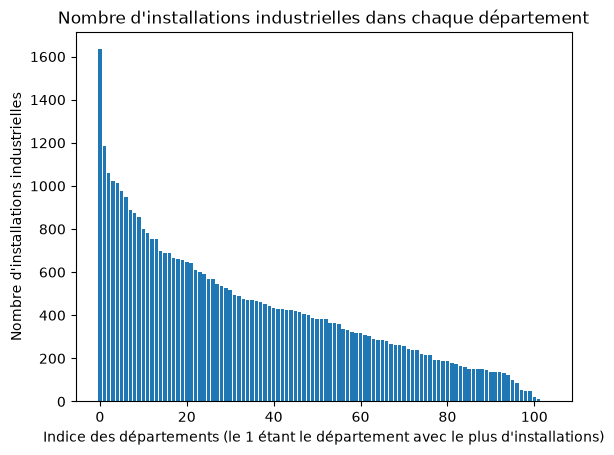

In [5]:
# On récupère donc la liste des installations industrielles
installations_indust = pd.read_csv(lien_stockage_physique_icpe, sep=";", encoding='utf-8')
print("On a ", installations_indust.shape[0], "installations industrielles.", end="")
installations_indust = installations_indust.loc[installations_indust["lib_regime"] != "Non ICPE"]
print(" Dont ", installations_indust.shape[0], "installations industrielles ICPE.")

#On veut garder uniquement les installations industrielles pures (pas l'agriculture et l'élevage par ex)
installations_indust = (installations_indust.loc[
    (installations_indust["industrie"] == 1)
    & (installations_indust["bovins"] == 0)
    & (installations_indust["porcs"] == 0)
    & (installations_indust["volailles"] == 0)
    & (installations_indust["eolienne"] == 0)
    ])
print("On ne garde que les ", installations_indust.shape[0], "installations industrielles pures.")

#On classe les départements qui ont le plus d'installations industrielles pour limiter la recherche (car les données sur Hub'eau sont trop volumineuses pour traiter la France entière)
classement_dpt = (installations_indust.groupby("num_dep")
    .size()
    .sort_values(ascending=False)
    )
plt.bar(range(classement_dpt.shape[0]), classement_dpt.values)
plt.title("Nombre d'installations industrielles dans chaque département")
plt.xlabel("Indice des départements (le 1 étant le département avec le plus d'installations)")
plt.ylabel("Nombre d'installations industrielles")

On va donc prendre le département qui contient le plus d'installations industrielles pour notre analyse.  
En effet, Hub'eau API nous donne un très grand volume de données et nous devons nous limiter dans notre recherche à quelques départements.  
Avec le graphique ci-dessus, on voit que le département 59 est de loin le plus grand centre industriel français.  
Nous nous concentrerons donc sur le département 59 pour la suite de l'analyse.  

In [6]:
departement_cible = classement_dpt.index[0]
print("Département analysé : ", departement_cible)

Département analysé :  59


Mise en forme des données géographiques avec Geopandas

In [7]:
installations_indust = installations_indust.loc[installations_indust["num_dep"] == departement_cible]

#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = installations_indust.loc[installations_indust["x"].isnull() | installations_indust["y"].isnull() | installations_indust["code_epsg"].isnull()].shape[0]
print(nb_position_less, "installations industrielles n'ont pas de coordonnées géographiques.")
installations_indust = installations_indust.loc[installations_indust["x"].notnull() & installations_indust["y"].notnull() & installations_indust["code_epsg"].notnull()]

#On utilise les coordonnées des installations pour les localiser avec Geopandas
installations_indust["geometry"] = None #Colonne qui va prendre la valeur position Geopandas
codes_epsg_type_coord = installations_indust["code_epsg"].unique()   #On veut que ça marche pour les différents types de référentiels (x,y)
for epsg in codes_epsg_type_coord:
    filtre = installations_indust["code_epsg"] == epsg
    points = gpd.points_from_xy(
        installations_indust.loc[filtre, "x"], 
        installations_indust.loc[filtre, "y"]
    )
    serie_geometrique = gpd.GeoSeries(points, crs=f"EPSG:{int(epsg)}")
    serie_geometrique = serie_geometrique.to_crs("EPSG:2154") #On ramène tout sous le même format
    installations_indust.loc[filtre, "geometry"] = serie_geometrique.values

#On définit un GeoDataFrame pour les études géométriques :
installations_indust = gpd.GeoDataFrame(installations_indust, geometry="geometry", crs="EPSG:2154")

0 installations industrielles n'ont pas de coordonnées géographiques.


### Récupération des données sur les nappes phréatiques du 59

L'API Hub'eau ne permet pas d'envoyer toutes les stations d'un coup.  
Encore moins toutes les chroniques d'un coup.  
Donc on sélectionne que la région pour laquelle on a vu qu'il y avait une grande concentration d'industrie : le 59

In [13]:
#On récupère les stations de mesure des nappes phréatiques sur le site Hubeau
url_stations = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/stations"
stations = []

params = {"code_departement": departement_cible, "size": 5000, "format": "json"}
fichier_stations = rq.get(url_stations, params=params)

if fichier_stations.status_code == 200:
    data = fichier_stations.json()
    stations.extend(data["data"])
    print("Fichier téléchargé.")
else:
    print(fichier_stations.status_code)
    print("Erreur avec le téléchargement du fichier stations Hubeau.")

stations = pd.DataFrame(stations)
stations.to_csv("../../data/stations_nappes.csv", encoding='utf-8')
print("On a récupéré ", stations.shape[0], "stations de mesure des nappes phréatiques dans le département ", departement_cible, ".")

Fichier téléchargé.
On a récupéré  730 stations de mesure des nappes phréatiques dans le département  59 .


Mise en forme des données géographiques avec Geopandas

In [14]:
#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = stations.loc[stations["x"].isnull() | stations["y"].isnull()].shape[0]
print(nb_position_less, "stations n'ont pas de coordonnées géographiques.")
stations = stations.loc[stations["x"].notnull() & stations["y"].notnull()]

#On crée le modèle Geopandas
stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations['x'], stations['y']),
    crs="EPSG:4326"
).to_crs(epsg=2154) #On ramène tout sous le même format que les installations industrielles

0 stations n'ont pas de coordonnées géographiques.


Pour chaque station identifiée dans les départements contenant le plus d'industrie, on récupère les séries temporelles de niveau des nappes phréatiques entre janvier 2015 et janvier 2026

In [15]:
#On ne peut pas récupérer le volume des nappes phréatiques pour toutes les stations en même temps.


#On veut récupérer les volumes des nappes phréatiques pour chaque station
url_chroniques_api = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/chroniques"
chroniques = []

#Quand on essaye de récupérer toutes les données de toutes les nappes, on a une erreur 414 : la requête URL est trop longue avec tous les code_bss en paramètres.
#Donc on va diviser les données de 700 stations à récupérer en paquets de 50.

liste_codes_bss_stations = stations["code_bss"].tolist()
paquets_intermediaires = []
for i in range(0, stations.shape[0], 50):
    paquets_intermediaires.append(liste_codes_bss_stations[i:i+50])
print("Nombre de stations par paquets : ", [len(x) for x in paquets_intermediaires])

for paquet in paquets_intermediaires:
    params_api = {"code_bss":",".join(paquet), "size":5000, "format":"json", "date_debut_mesure":"2015-01-01", "date_fin_mesure":"2026-01-01"}

    #Le problème est que le volume de données retourné est trop important. => On obtient une erreur 206 pour chaque paquet.
    #Il faut donc récupérer les premières informations renvoyées par l'API et aller chercher la page suivante.
    url = url_chroniques_api
    while url != None:
        try:
            fichier_chroniques = rq.get(url, params=params_api, timeout=20)    #On met un timeout pour rapidement recommencer la requête si ça marche pas.
        except Exception as e:
            print("Erreur requête : ", end="")
            print(e)
            print("Pas grave, on va réessayer.")
            continue
           #On recommence en haut de la boucle sur la même URL
        if fichier_chroniques.status_code == 200 or fichier_chroniques.status_code == 206:
            data = fichier_chroniques.json()
            chroniques.extend(data["data"])
            url = data.get("next")
            params_api = None   #Il semble que cette information soit déjà intégrée dans l'url de la page "next"
            print("Sous-paquet téléchargé.")
            time.sleep(1)   #On attend 1 sec pour éviter de se faire rejeter par le serveur
        else:
            print(fichier_chroniques.status_code)
            print("Erreur avec le téléchargement du fichier stations Hubeau.")
            time.sleep(1)   #On attend 1 seconde et on recommence au cas où ça se répare tout seul
print("Téléchargement des donné réussi !")

chroniques = pd.DataFrame(chroniques)
chroniques.to_csv("../../data/chroniques_nappes.csv", encoding='utf-8')

Nombre de stations par paquets :  [50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 30]
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Téléchargement de

On nettoie les données des séries temporelles des nappes phréatiques

In [16]:
chroniques['date_mesure'] = pd.to_datetime(chroniques['date_mesure'])
print("Nombre de chroniques sans niveau d'eau : ", chroniques.loc[chroniques["niveau_nappe_eau"].isnull()].shape[0])
#On supprime les chroniques pour lesquelles le niveau d'eau est NULL
chroniques = chroniques.loc[chroniques["niveau_nappe_eau"].notnull()]

Nombre de chroniques sans niveau d'eau :  0


## Test des données

Un exemple de série temporelle pour une station (nappe phréatique)

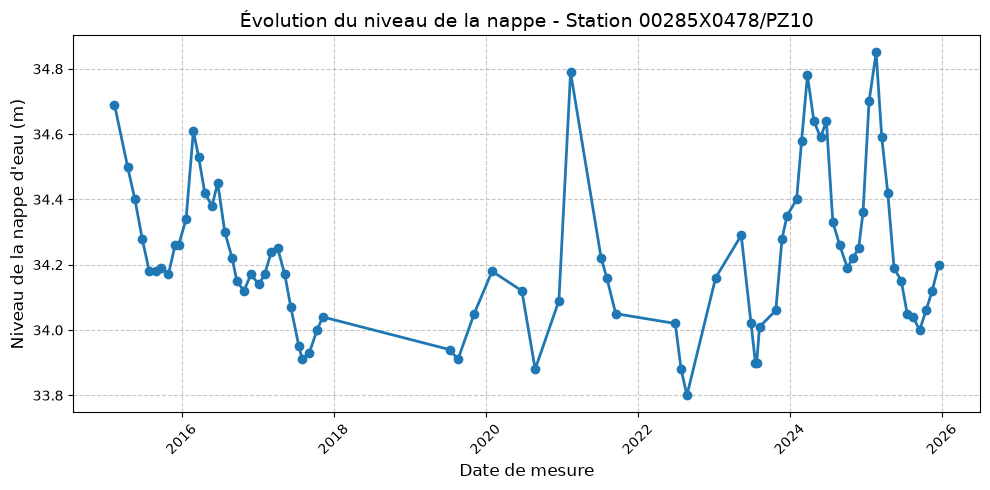

In [17]:
# Représentation d'une série temporelle d'une station
station_cible = '00285X0478/PZ10'
df_station = chroniques[chroniques['code_bss'] == station_cible]
df_station = df_station.sort_values(by='date_mesure')

plt.figure(figsize=(10, 5))
plt.plot(
    df_station['date_mesure'], 
    df_station['niveau_nappe_eau'], 
    marker='o',         # Ajoute un point sur chaque mesure réelle
    linestyle='-',      # Relie les points par une ligne
    color='#1f77b4', 
    linewidth=2
)

plt.title(f"Évolution du niveau de la nappe - Station {station_cible}", fontsize=14)
plt.xlabel("Date de mesure", fontsize=12)
plt.ylabel("Niveau de la nappe d'eau (m)", fontsize=12)
plt.xticks(rotation=45) # Penche les dates pour éviter qu'elles ne se superposent
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Nettoyage et standardisation des données

Les séries temporelles de Hub'eau donnent des mesures des nappes phréatiques à des dates différentes entre les stations.  
Pour les calculs futurs, on va standardiser ça en faisant une moyenne par station et par mois

In [18]:
chroniques['date_mois_annee'] = chroniques['date_mesure'].dt.to_period('M')
chroniques

chroniques_niveau_mensuel = (chroniques.groupby(["code_bss", "date_mois_annee"])
              .agg({
                  "niveau_nappe_eau":"mean",
                  "profondeur_nappe":"mean"
              })
              .reset_index()
    )
chroniques_niveau_mensuel["date_mesure"] = chroniques_niveau_mensuel["date_mois_annee"].dt.to_timestamp()
chroniques_niveau_mensuel['date_mesure'] = pd.to_datetime(chroniques_niveau_mensuel['date_mesure'])
print("Les données ont été normalisées en moyenne par mois pour chaque station.")

Les données ont été normalisées en moyenne par mois pour chaque station.


# 1. Répartition des usines et des stations hydrologiques dans le Nord

Text(0.5, 1.0, 'Répartition des usines ICPE et des stations hydrologiques dans le département')

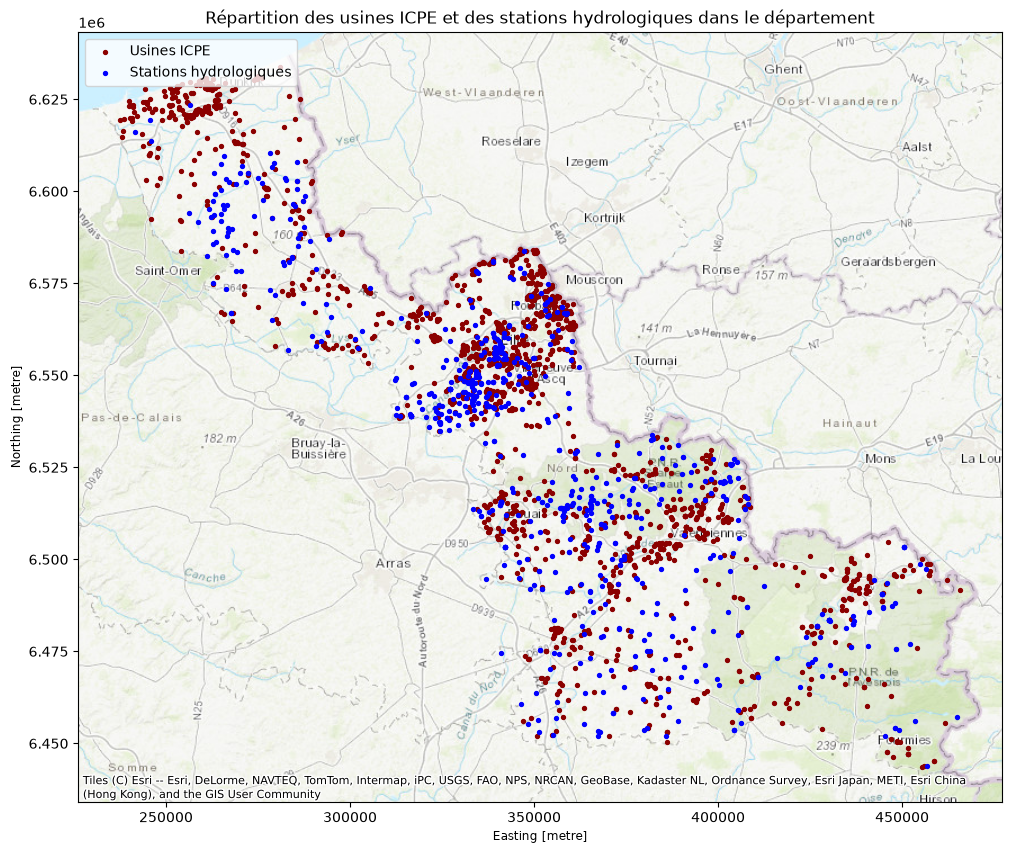

In [19]:
# Stations (points bleus, taille réduite, avec un fin contour blanc pour la lisibilité)
ax = plt.subplots(figsize=(12, 10))[1]
installations_indust.to_crs(epsg=3857).plot(ax=ax, color="darkred", markersize=8, label="Usines ICPE", zorder=1)
stations.to_crs(epsg=3857).plot(ax=ax, color="blue", markersize=8, label="Stations hydrologiques", zorder=2)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap)
plt.legend(loc="upper left")
plt.title("Répartition des usines ICPE et des stations hydrologiques dans le département")

## On cherche la quantité d'usines par station

In [20]:
#On veut le nombre d'usines qui sont dans les 5km de chaque station
r = 5 * 1000

stations_rayon = stations.copy()
stations_rayon["geometry"] = stations_rayon.geometry.buffer(r)  #On suppose que la station prend toute la place dans un rayon de 5km autour du point où elle est réellement

usines_ds_rayon = gpd.sjoin(installations_indust, stations_rayon, how="inner", predicate="within")
nb_usine_ds_rayon = usines_ds_rayon.groupby("code_bss").size().reset_index(name="nb_usines_5km")

stations = stations.merge(nb_usine_ds_rayon, on="code_bss", how="left")
stations["nb_usines_5km"] = stations["nb_usines_5km"].fillna(0).astype(int) #On remplace les valeurs nulles par 0

#On rajoute une colonne dans le tableau chroniques qui indique la pression industrielle (nb d'usines dans un rayon de 5km qui exploitent probablement la nappe)
chroniques = chroniques.merge(stations[["code_bss", "nb_usines_5km"]], on="code_bss", how="inner")


In [25]:
installations_indust.head()

,code_aiot,x,y,code_epsg,nom_ets,num_dep,adresse,cd_insee,cd_postal,commune,...,industrie,ied,priorite_nationale,rubriques_autorisation,rubriques_enregistrement,rubriques_declaration,date_modification,derniere_inspection,url_fiche,geometry
19,7000923,660867,7093426,2154,TIM,59,Route de Socx - BP 49,59478,59380,Quaëdypre,...,1,0,0,NaN,NaN,NaN,2025/10/17 00:00:00,2025/08/27 00:00:00,https://www.georisques.gouv.fr/risques/install...,POINT (660867 7093426)
96,7002039,712397,7034607,2154,EPC - FRANCE,59,rue du pont des vaches,59239,59148,Flines-lez-Raches,...,1,0,1,4220,NaN,NaN,2026/09/15 00:00:00,2025/05/15 00:00:00,https://www.georisques.gouv.fr/risques/install...,POINT (712397 7034607)
105,7002370,731734,6998404,2154,TRITUBE,59,29 rue Jeanne d'arc,59074,59980,Bertry,...,1,0,0,NaN,NaN,NaN,2025/02/28 00:00:00,2010/07/26 00:00:00,https://www.georisques.gouv.fr/risques/install...,POINT (731734 6998404)
111,7003032,713665,7009892,2154,LE COMPTOIR DE LA FESTIVITE,59,Zone d'Actipôle de l'A2 - BP 23,59488,59554,Raillencourt-Sainte-Olle,...,1,0,0,NaN,NaN,NaN,2025/09/09 00:00:00,2014/12/16 00:00:00,https://www.georisques.gouv.fr/risques/install...,POINT (713665 7009892)
126,7004083,741459,7037024,2154,HANOT Jean-Marc,59,"454, rue Gambetta",59253,59970,Fresnes-sur-Escaut,...,1,0,0,NaN,NaN,NaN,2025/02/28 00:00:00,2019/06/28 00:00:00,https://www.georisques.gouv.fr/risques/install...,POINT (741459 7037024)


In [23]:
stations.head()

,code_bss,urn_bss,date_debut_mesure,date_fin_mesure,code_commune_insee,nom_commune,x,y,codes_bdlisa,urns_bdlisa,...,nb_mesures_piezo,code_departement,nom_departement,libelle_pe,profondeur_investigation,codes_masse_eau_edl,noms_masse_eau_edl,urns_masse_eau_edl,date_maj,nb_usines_5km
0,00274X0010/F10,http://services.ades.eaufrance.fr/pointeau/002...,1957-12-07,1983-12-12,59456,Pecquencourt,3.215697,50.377296,[121BD],[http://reseau.eaufrance.fr/geotraitements/bdl...,...,595,59,Nord,NaN,69.00,[AG306],[Craie des vallées de la Scarpe et de la Sensée],[http://www.sandre.eaufrance.fr/geo/MasseDEauS...,Fri Jun 28 07:31:38 CEST 2024,32
1,00202A0131/F10,http://services.ades.eaufrance.fr/pointeau/002...,1974-02-02,2001-04-15,59316,Houplin-Ancoisne,3.001704,50.563558,[121BD],[http://reseau.eaufrance.fr/geotraitements/bdl...,...,83,59,Nord,NaN,45.10,[AG303],[Craie de la vallée de la Deûle],[http://www.sandre.eaufrance.fr/geo/MasseDEauS...,Fri Jun 28 07:31:38 CEST 2024,97
2,00148A0012/F10,http://services.ades.eaufrance.fr/pointeau/001...,1963-01-30,1983-12-02,59009,Villeneuve-d'Ascq,3.182847,50.643541,None,[],...,183,59,Nord,NaN,84.25,[AG303],[Craie de la vallée de la Deûle],[http://www.sandre.eaufrance.fr/geo/MasseDEauS...,Fri Jun 28 07:31:38 CEST 2024,75
3,00146C0077/F10,http://services.ades.eaufrance.fr/pointeau/001...,1974-02-01,2001-04-15,59193,Emmerin,3.001564,50.593370,[121BD],[http://reseau.eaufrance.fr/geotraitements/bdl...,...,87,59,Nord,NaN,20.00,[AG303],[Craie de la vallée de la Deûle],[http://www.sandre.eaufrance.fr/geo/MasseDEauS...,Fri Jun 28 07:31:38 CEST 2024,108
4,00201C0530/PZ10,http://services.ades.eaufrance.fr/pointeau/002...,2001-04-15,2001-04-15,59011,Annœullin,2.916410,50.534827,None,[],...,1,59,Nord,NaN,20.00,[AG303],[Craie de la vallée de la Deûle],[http://www.sandre.eaufrance.fr/geo/MasseDEauS...,Fri Jun 28 07:31:38 CEST 2024,17


In [26]:
chroniques.head()

,code_bss,bss_id,urn_bss,date_mesure,timestamp_mesure,niveau_nappe_eau,mode_obtention,statut,qualification,code_continuite,nom_continuite,code_producteur,nom_producteur,code_nature_mesure,nom_nature_mesure,profondeur_nappe,date_mois_annee,nb_usines_5km
0,00285X0478/PZ10,BSS000CXYT,http://services.ades.eaufrance.fr/pointeau/002...,2015-02-12,1423699200000,34.69,Valeur mesurée,Donnée contrôlée niveau 1,Correcte,1,Point initial,20004619100025,Syndicat Mixte Escaut et Affluents (2000461910...,NaN,NaN,34.69,2015-02,21
1,00285X0478/PZ10,BSS000CXYT,http://services.ades.eaufrance.fr/pointeau/002...,2015-04-16,1429142400000,34.50,Valeur mesurée,Donnée contrôlée niveau 1,Correcte,2,Point lié au point précédent,20004619100025,Syndicat Mixte Escaut et Affluents (2000461910...,NaN,NaN,34.50,2015-04,21
2,00285X0478/PZ10,BSS000CXYT,http://services.ades.eaufrance.fr/pointeau/002...,2015-05-21,1432166400000,34.40,Valeur mesurée,Donnée contrôlée niveau 1,Correcte,2,Point lié au point précédent,20004619100025,Syndicat Mixte Escaut et Affluents (2000461910...,NaN,NaN,34.40,2015-05,21
3,00285X0478/PZ10,BSS000CXYT,http://services.ades.eaufrance.fr/pointeau/002...,2015-06-25,1435190400000,34.28,Valeur mesurée,Donnée contrôlée niveau 1,Correcte,2,Point lié au point précédent,20004619100025,Syndicat Mixte Escaut et Affluents (2000461910...,NaN,NaN,34.28,2015-06,21
4,00285X0478/PZ10,BSS000CXYT,http://services.ades.eaufrance.fr/pointeau/002...,2015-07-29,1438128000000,34.18,Valeur mesurée,Donnée contrôlée niveau 1,Correcte,2,Point lié au point précédent,20004619100025,Syndicat Mixte Escaut et Affluents (2000461910...,NaN,NaN,34.18,2015-07,21


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Conversion des dates au bon format
chroniques['date_mesure'] = pd.to_datetime(chroniques['date_mesure'])
chroniques['annee'] = chroniques['date_mesure'].dt.year
chroniques['mois_annee'] = chroniques['date_mesure'].dt.to_period('M')

# Création des 3 catégories de densité industrielle basées sur les terciles (33%, 66%)
chroniques['densite_industrielle'] = pd.qcut(
    chroniques['nb_usines_5km'], 
    q=3, 
    labels=['Faible densité', 'Densité moyenne', 'Forte densité industrielle']
)


In [35]:
# 1. Isoler le niveau initial (le plus ancien) pour chaque station
niveaux_ref = chroniques.sort_values(['code_bss', 'date_mesure']).groupby('code_bss')['niveau_nappe_eau'].first().reset_index()
niveaux_ref.rename(columns={'niveau_nappe_eau': 'niveau_ref'}, inplace=True)

# 2. Intégrer ce niveau de référence et calculer l'indice Base 100
chroniques = chroniques.merge(niveaux_ref, on='code_bss')
chroniques['indice_base100'] = (chroniques['niveau_nappe_eau'] / chroniques['niveau_ref']) * 100

# 3. Calculer l'évolution moyenne par mois et par catégorie
# (L'ajout de observed=False évite un avertissement Pandas sur les variables catégorielles)
evolution = chroniques.groupby(['mois_annee', 'densite_industrielle'], observed=False)['indice_base100'].mean().unstack()

evolution.index = evolution.index.to_timestamp()

# 4. Tracer le graphique
plt.figure(figsize=(12, 6))
sns.lineplot(data=evolution)
plt.title("Évolution du niveau des nappes (Base 100) selon la densité industrielle locale")
plt.ylabel("Indice du niveau d'eau (Base 100 au 1er relevé)")
plt.xlabel("Date")
plt.axhline(100, color='grey', linestyle='--', alpha=0.5)
plt.legend(title="Densité (Rayon 5km)")
plt.grid(True, alpha=0.3)
plt.show()



KeyError: 'niveau_ref'

In [34]:
# 1. Calculer la moyenne du niveau d'eau pour l'année de départ (2015) et l'année de fin (2025)
df_2015 = chroniques[chroniques['annee'] == 2015].groupby(['code_bss', 'densite_industrielle'])['niveau_nappe_eau'].mean().reset_index()
df_2025 = chroniques[chroniques['annee'] == 2025].groupby('code_bss')['niveau_nappe_eau'].mean().reset_index()

# 2. Fusionner et calculer la baisse en mètres (différence brute)
diff_df = pd.merge(df_2015, df_2025, on='code_bss', suffixes=('_2015', '_2025'))
diff_df['variation_metres'] = diff_df['niveau_nappe_eau_2025'] - diff_df['niveau_nappe_eau_2015']

# 3. Résumer les résultats par catégorie
tableau_final = diff_df.groupby('densite_industrielle').agg(
    nombre_stations=('code_bss', 'count'),
    baisse_moyenne_metres=('variation_metres', 'mean')
).reset_index()

# 4. Calcul de l'amplification (Différence entre Forte densité et Faible densité)
baisse_rurale = tableau_final.loc[tableau_final['densite_industrielle'] == 'Faible densité', 'baisse_moyenne_metres'].values[0]
baisse_industrielle = tableau_final.loc[tableau_final['densite_industrielle'] == 'Forte densité industrielle', 'baisse_moyenne_metres'].values[0]
amplification = baisse_industrielle - baisse_rurale

print(tableau_final.to_markdown(index=False))
print(f"\nAmplification industrielle estimée : La baisse est aggravée de {abs(amplification):.2f} mètres dans les zones denses.")


ImportError: `Import tabulate` failed.  Use pip or conda to install the tabulate package.